## Lab 4 — Z-transforms and difference equations

This lab consists of three questions exploring the Z-transform and difference equations:

1. **Z-transforms:** The definition of the Z-transform, and the role of the region of convergence.
2. **Difference equations with initial conditions:** Solving difference equations with the Z-transform and decomposing the response into its zero-state/zero-input components.
3. **Audio filtering:** Using difference equations to approximate the idealized band-pass filters that we explored in Lab 3.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import lab_tools as lab
%matplotlib inline

## Q1: What is a Z-transform?

### 1A. The weighted sum

Let's start with a simple real-valued discrete-time sequence:
$$h[n]=0.6^n\quad(n\geq0),\qquad h[n]=0\quad(n<0).$$

Its first 20 samples are illustrated below.

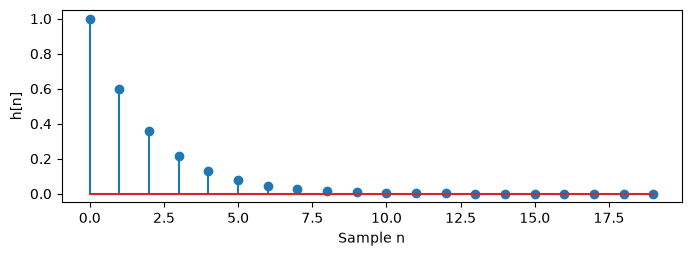

In [2]:
n = np.arange(20)
plt.figure(figsize=(8, 2.5))
plt.stem(n, 0.6 ** n)
plt.xlabel("Sample n")
plt.ylabel("h[n]")
plt.show()

For a complex number, $z$, the **Z-transform** multiplies each value of the signal by $z^{-n}$ and computes their sum:
$$H(z)=\sum_{n=-\infty}^{\infty}h[n]z^{-n}.$$
For our signal, this is a geometric series:
$$H(z)=1+\frac{0.6}{z}+\left(\frac{0.6}{z}\right)^2+\cdots
=\frac{1}{1-0.6/z}=\frac{z}{z-0.6}.$$
The values of $z$ where this sum converges form the **region of convergence (ROC)** of the signal. For this signal, the ROC is $|0.6/z|<1$, or $|z|>0.6$. As described in the lecture, the Z-transform consists of **both** the algebraic expression as well as the ROC. The following cell computes the values $z^{-n}$ for the supplied values of $n$.

In [3]:
def weight(n, z):
    """Return the Z-transform weights z**(-n) at the sample indices n."""
    return z ** (-n)

weight(np.arange(3), 2.0)

array([1.  , 0.5 , 0.25])

### 1B. Poles and zeros

Now, let's consider a slightly more complicated Z-transform expression:
$$H(z)=\frac{z}{z-0.6}+\frac{z}{z-1.2}.$$
A **pole** is an uncancelled denominator root of the expression. As you approach a pole, the Z-transform expression grows uncontrollably large. A **zero**, on the other hand, reduces the expression to $0$. For this expression, the poles are 0.6 and 1.2 while the zeros are 0 and 0.9.

Below, we describe $H(z)$ in terms of its numerator (`b`) and denominator (`a`) coefficients in decreasing powers of $z$:
$$
    H(z) = \frac{z}{z - 0.6} + \frac{z}{z - 1.2} = \frac{2z^2 - 1.8z}{(z - 0.6)(z - 1.2)} = \frac{2z^2 - 1.8z}{z^2 - 1.8z + 0.72}
$$ 
As discussed in class, each possible ROC for this expression is a circular region bounded by circles containing the poles. For this expression with two poles, this gives us three possible ROCs. Run the code below and change the region to see each of the possible ROCs in the plot below.

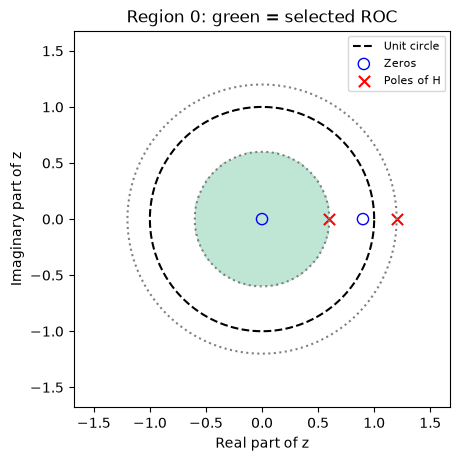

In [4]:
# Coefficients of numerator and denominator polynomials
b = [2, -1.8]
a = [1, -1.8, 0.72]
region = 0  # Try 0, 1, and 2.
model = lab.z_explorer(b, a, region=region, view="plane")

In the next plot, we will plot the magnitude $|H(z)|$ to inspect its behavior around the poles. This is a 3D, interactive plot which can be dragged and re-oriented for better visualization. As you can see the magnitude rises rapidly around the poles. As in the 2D plot, the green region denotes the chosen ROC.

In [5]:
model = lab.z_explorer(b, a, region=region, view="surface", interactive=True)

### 1C. Why is the ROC important?

The Z-transform expression does not uniquely specify the original signal. For our original expression $z/(z - 0.6)$, there are two signals with the same expression:
$$h[n] = 0.6^n\ (n\geq0), \quad |z|>0.6,$$
and
$$h[n] = - (0.6)^n\ (n<0), \quad |z|<0.6.$$

To decide which one we should select, we need the ROC. To obtain the right-sided inverse, we choose the exterior ROC. Similarly, to obtain the left-sided inverse, we choose the interior ROC. 

For our rational expression, the Z-transform is the sum of two terms and we'll invert each of them corresponding to the chosen ROC:

1. Region 0: This region is inside both poles. So, we'll choose the left-sided inverse for both terms.
2. Region 1: This region is outside the pole at $0.6$ and inside the pole at $1.2$. So, we'll choose the right-sided inverse for the first term and left-sided inverse for the second.
3. Region 2: This region is outside both poles. So, we'll choose the right-sided inverse for both.

Run the next cell to see what these inverses correspond to.

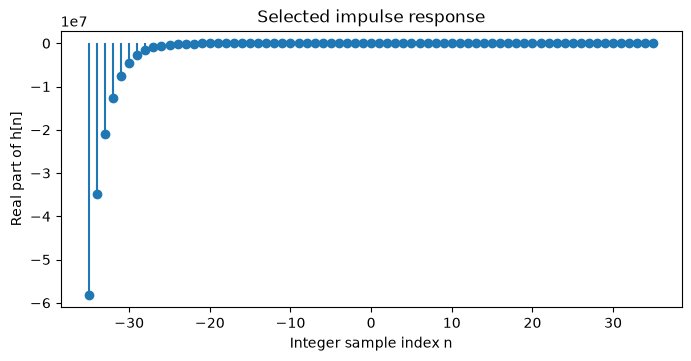

In [6]:
lab.roc_sums(model, view="sequence")

Suppose the expression corresponded to the impulse response of a discrete-time LTI system. For each ROC, identify whether the impulse response is left-sided, right-sided, or two-sided, and whether the system is causal and BIBO stable.

- Region 0: $|z|<0.6$ → **left-sided** ($h[n]=0$ for all $n\ge0$), **not causal** (it is anti-causal), **not BIBO stable**.
- Region 1: $0.6<|z|<1.2$ → **two-sided**, **not causal**, **BIBO stable**.
- Region 2: $|z|>1.2$ → **right-sided**, **causal**, **not BIBO stable**.

**1C Answers: the impulse responses and why**

Split into the two terms, $H(z)=\dfrac{1}{1-0.6z^{-1}}+\dfrac{1}{1-1.2z^{-1}}$, and invert each with the ROC: outside a pole $p$ gives $p^n u[n]$ (right-sided), inside gives $-p^n u[-n-1]$ (left-sided).

| Region | ROC | $h[n]$ | Some values | Side | Causal? | Stable? |
|---|---|---|---|---|---|---|
| 0 | $\lvert z\rvert<0.6$ | $-(0.6^n+1.2^n)\,u[-n-1]$ | $h[-1]=-2.5,\ h[-5]=-13.3,\ h[-35]\approx-5.8\times10^{7}$ | left | no | no |
| 1 | $0.6<\lvert z\rvert<1.2$ | $0.6^n u[n]-1.2^n u[-n-1]$ | $h[0]=1,\ h[1]=0.6,\ h[-1]=-0.833,\ h[-5]=-0.40$ | two-sided | no | **yes**, $\sum\lvert h\rvert=2.5+5=7.5$ |
| 2 | $\lvert z\rvert>1.2$ | $(0.6^n+1.2^n)\,u[n]$ | $h[0]=2,\ h[10]=6.2,\ h[35]\approx591$ | right | **yes** | no |

The rules (you can read them straight off the plane plot, without inverting anything):
- **BIBO stable ⇔ $\sum_n|h[n]|<\infty$ ⇔ the unit circle $|z|=1$ is in the ROC.** On $|z|=1$ we have $|h[n]z^{-n}|=|h[n]|$, so "the sum converges on the unit circle" *is* absolute summability (the DTFT, i.e. the frequency response, exists). Only Region 1 contains $|z|=1$ (since $0.6<1<1.2$).
- **Causal ⇔ $h[n]=0$ for $n<0$ ⇔ the ROC is the outside of the outermost pole (including $z=\infty$).** Only Region 2.
- Region 0 blows up to the *left*: for $n\to-\infty$, $0.6^n=(1/0.6)^{|n|}=1.67^{|n|}$ grows. Region 2 blows up to the *right*: $1.2^n$ grows.
- **Causal *and* stable would need every pole inside the unit circle.** The pole at $1.2$ makes that impossible, so for this $H(z)$ you have to choose one or the other.

(The saved plot above shows Region 0, the default. Change `region` in the 1B cell and re-run 1B → 1C to see Regions 1 and 2.)

### 1D. What happens outside the ROC?

The rational expression is defined everywhere except at its poles, but outside the selected ROC it does **not** equal the Z-transform sum. The Z-transform sum is not defined out side the ROC. Choose Region 1 below and inspect two values: $z=0.9$ inside that ROC and $z=1.5$ outside it.

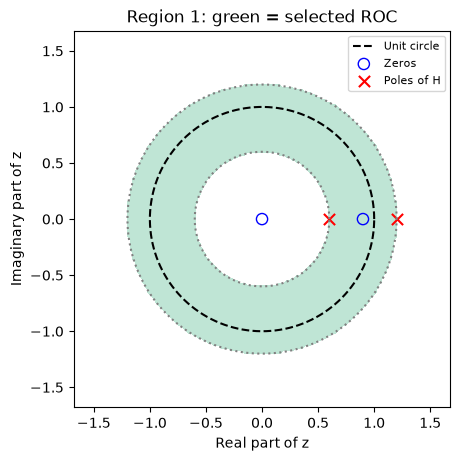

In [7]:
region = 1
model = lab.z_explorer(b, a, region=region, view="plane")

Here, we'll inspect the maagnitudes of the weighted terms $h[n]z^{-n}$ that appear in the Z-transform sum.

1) What do you observe about these terms for for $z = 0.9$?
2) What about for $z = 1.5$?

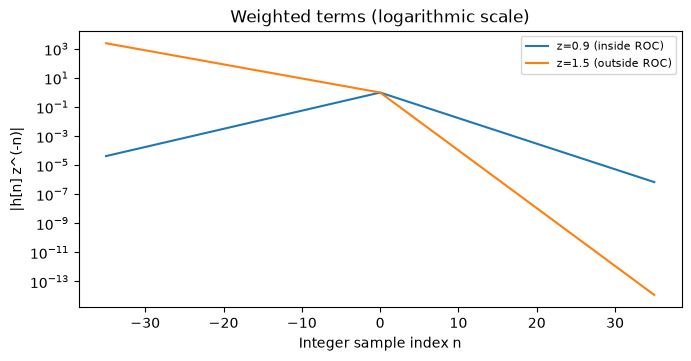

In [8]:
lab.roc_sums(model, points=(0.9, 1.5), view="terms")

**1D Answers: the weighted terms**

In Region 1, $h[n]=0.6^n$ for $n\ge0$ and $-1.2^n$ for $n<0$, so every weighted term is a geometric sequence:

| | right tail, $n\ge0$: $\lvert h[n]z^{-n}\rvert=(0.6/\lvert z\rvert)^n$ | left tail, $n=-m<0$: $\lvert h[n]z^{-n}\rvert=(\lvert z\rvert/1.2)^m$ |
|---|---|---|
| $z=0.9$ (inside) | $(2/3)^n$, decays ($6.9\times10^{-7}$ at $n=35$) | $(3/4)^m$, decays ($4.2\times10^{-5}$ at $n=-35$) |
| $z=1.5$ (outside) | $0.4^n$, decays ($1.2\times10^{-14}$ at $n=35$) | $1.25^m$, **grows** ($2.5\times10^{3}$ at $n=-35$) |

1) **$z=0.9$:** the terms shrink geometrically in *both* directions (two straight lines going down on the log plot, peak 1 at $n=0$). Terms that shrink geometrically are summable.
2) **$z=1.5$:** the right tail still shrinks (even faster), but the **left tail grows without bound** as $n\to-\infty$. If the terms don't even go to zero, the sum cannot converge.

Why: the right-sided piece (pole $0.6$) needs $|z|>0.6$ and the left-sided piece (pole $1.2$) needs $|z|<1.2$. $z=1.5$ breaks the second condition.

Now, let's see what happens when we try to sum up the weighted terms to try and comptue the Z-transform. We'll do this by taking **partial sums** and then seeing if they converge:
$$S_M=\sum_{n=-M}^{M}h[n]z^{-n}.$$
In the plot below, we'll plot the difference between $S_M$ and the rational formula. What happens to the difference when:

1) For the value inside the ROC $z = 0.9$?
2) For the value outside the ROC $z = 1.5$?

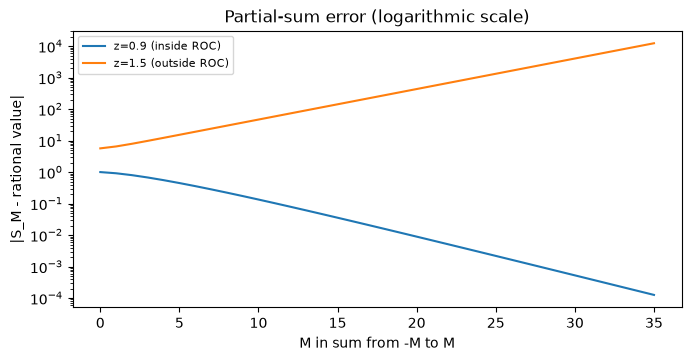

In [9]:
lab.roc_sums(model, points=(0.9, 1.5), view="sums")

**1D Answers: the partial sums**

| $M$ | 0 | 10 | 20 | 35 |
|---|---|---|---|---|
| error at $z=0.9$ | 1 | 0.134 | 0.0089 | $1.3\times10^{-4}$ |
| error at $z=1.5$ | 5.67 | 46.6 | 434 | $1.2\times10^{4}$ |

1) **$z=0.9$ (inside the ROC): the error goes to 0.** It shrinks by a factor $\approx0.75$ per extra term (the slower of the two ratios $2/3$ and $3/4$), which is the straight downward line on the log plot. So $S_M$ converges to the rational formula. (Detail: $z=0.9$ happens to be the **zero** of $H$, so the limit is $H(0.9)=0$. The right tail sums to $0.9/0.3=3$ and the left tail to $-3$.)
2) **$z=1.5$ (outside the ROC): the error grows by a factor $1.25$ per step.** The partial sums run off to $-\infty$ ($S_{35}\approx-1.2\times10^4$). The formula still produces a number, $H(1.5)=1.5/0.9+1.5/0.3=6.67$, but **that number is not the sum of this signal's series.** It is the value of the *Region 2* signal's Z-transform, where both $(0.6/1.5)^n$ and $(1.2/1.5)^n$ decay.

The algebraic expression is defined everywhere except at the poles, but it only *equals* $\sum h[n]z^{-n}$ inside the ROC. That is why a Z-transform is "expression **+** ROC".

## Q2 — Exploring LCCDEs

### 2A. How do initial conditions affect the output signal of an LCCDE?

For this question, we will analyze a discrete-time system with real input $x[n]$ and output $y[n]$. As we saw in the lecture, LCCDEs provide a rule to generate the output signal from the input signal and possibly a set of initial conditions. We will analyze the following simple LCCDE:
$$y[n] = a\,y[n-1] + x[n],\qquad n\geq0.$$
We would like to understand what future values of $y$ will be. As we saw in the lecture, just knowing the difference equation isn't enough. We also need the **initial condition** $y[-1]=y_{-1}$, the stored output just before $n=0$.

In the cell below, we simulate the difference equation for different values of $a$ and constant input $x[n]=c$ for $n\geq0$. The function takes as input the initial condition, the values of $a$ and $c$, and plots the first few terms of this sequence. Try different values and observe how the solution changes for different values of $a$, $c$, and $y_{-1}$.

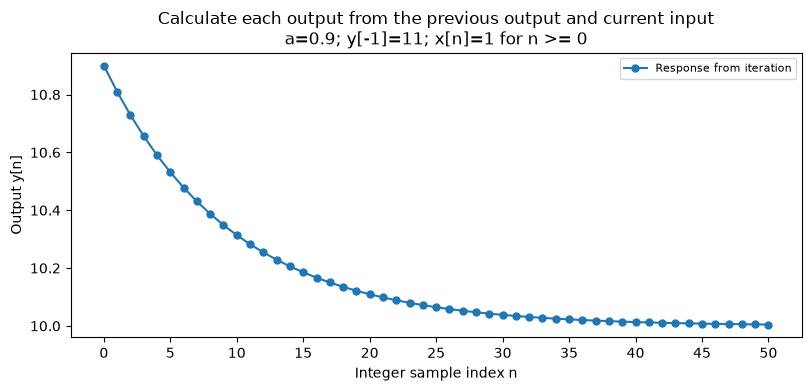

In [10]:
decay = 0.9  # a in the difference equation
initial = 11  # y[-1]
input_level = 1  # c in x[n] = c
experiment = lab.initial_condition_demo(decay, initial, input_level, view="response", steps = 50)

**2A Questions**

Set `decay = 0.9` and `input_level = 1`

1) How does changing the initial value (`initial`) change the behavior of the output signal? Is the signal increasing or decreasing? 
2) What steady-state value does the signal converge to eventually? Does it change with `decay`? For this question, keep `decay` between $0$ and $1$.

**2A Answers** (`decay` $a=0.9$, `input_level` $c=1$)

Trick: measure everything relative to 10. If $y[n]=10+e[n]$, then $e[n]=0.9\,e[n-1]$, so
$$y[n]-10=0.9^{\,n+1}\,(y_{-1}-10).$$
The gap to 10 shrinks by 10% every sample.

1) **The initial value sets the starting point and direction, not the destination.**

| `initial` $y_{-1}$ | $y[0],\,y[1],\,y[2]$ | behaviour | $y[50]$ |
|---|---|---|---|
| 11 (default) | 10.9, 10.81, 10.73 | **decreasing** towards 10 | 10.005 |
| 20 | 19, 18.1, 17.29 | decreasing | 10.05 |
| 10 | 10, 10, 10 | constant: already at the steady state | 10 |
| 4 | 4.6, 5.14, 5.63 | **increasing** towards 10 | 9.97 |
| 0 | 1, 1.9, 2.71 | increasing | 9.95 |

Start above 10 and the output falls; start below and it rises. It is monotonic because $a>0$.

2) **Steady state $=c/(1-a)=1/(1-0.9)=10$.** Set $y[n]=y[n-1]=y_{ss}$ in the equation: $y_{ss}=a\,y_{ss}+c$. It does not depend on the initial value. It **does depend on `decay`** (and is proportional to $c$: $c=2\to20$, $c=-1\to-10$):

| $a$ | $c/(1-a)$ | samples to close 99% of the gap, $\ln 0.01/\ln a$ | $y[50]$ from $y_{-1}=11$ |
|---|---|---|---|
| 0 | 1 | immediate | 1 |
| 0.5 | 2 | 7 | 2.000 |
| 0.9 | 10 | 44 | 10.005 |
| 0.99 | 100 | 458 | 46.7 (still climbing) |

A larger `decay` gives a higher steady state *and* a slower approach to it (the system has a longer memory).

Beyond $0<a<1$:
- $a=-0.5$: alternates sign while converging to $1/1.5=0.667$ ($-4.5,\ 3.25,\ -0.63,\ 1.31,\dots$). $a=-0.9$: same, but slower, to $0.526$.
- $a=1$: a ramp, $y[n]=y_{-1}+c(n+1)=12,13,14,\dots$ (62 at $n=50$), with no steady state ($c/(1-a)$ divides by zero).
- $a=-1$: never settles: $-10,\,11,\,-10,\,11,\dots$
- $a=1.1$: blows up (2702 at $n=50$). $c/(1-a)=-10$ is still a fixed point, but it pushes the output away. $a=-1.1$: blows up while alternating.

So the output settles **iff $|a|<1$**, i.e. iff the pole $z=a$ is inside the unit circle. The value matches the lecture's final value theorem: $\lim y[n]=\lim_{z\to1}(1-z^{-1})Y_+(z)=c/(1-a)$.

### 2B. The unilateral Z-transform

In Q1, the Z-transform summed over all integer indices. However, to solve difference equations with initial conditions, the **unilateral Z-transform** is often more convenient:
$$Y_+(z)=\sum_{n=0}^{\infty}y[n]z^{-n}
=y[0]+y[1]z^{-1}+y[2]z^{-2}+\cdots.$$

The unilateral Z-transform allows us to directly account for initial conditions through the delay formula below:
$$\sum_{n=0}^{\infty} y[n-1]z^{-n} = y_{-1}+z^{-1}Y_+(z).$$

Let $X_+(z)$ denote the unilateral Z-transform of the input. Applying the shift formula to our difference equation gives:
$$Y_+=a\bigl(y_{-1}+z^{-1}Y_+\bigr)+X_+.$$

Rearranging the above equation, the Z-transform of the output decomposes into two terms. The first depends on the initial condition and the second on the input signal.
$$Y_+(z)=\underbrace{\frac{a y_{-1}}{1-az^{-1}}}_{\text{Initial condition}}
+\underbrace{\frac{X_+(z)}{1-az^{-1}}}_{\text{Input signal}}.$$

Now, we can invert the above expression (choosing the outer ROC). The output now has two contributions corresponding to the initial condition and the input signal.
$$\boxed{y[n] = \underbrace{y_{-1}a^{n+1}}_{\text{Zero-input Response}} + \underbrace{c\,\frac{1-a^{n+1}}{1-a}}_{\text{Zero-state Response}},\qquad n\geq0,\quad a\ne1.}$$

**Question:** If we omit $y_{-1}$ from the shift rule, which initial value is assumed? Which of the zero-input or zero-state responses survive?

**2B Answer**

Where the $y_{-1}$ comes from: split off the $n=0$ term of the sum, which is the only one that reaches back before $n=0$:
$$\sum_{n=0}^{\infty}y[n-1]z^{-n}=\underbrace{y[-1]}_{n=0\text{ term}}+\sum_{n=1}^{\infty}y[n-1]z^{-n}
=y_{-1}+z^{-1}\sum_{m=0}^{\infty}y[m]z^{-m}=y_{-1}+z^{-1}Y_+(z).$$

- **If we omit $y_{-1}$** (use $\sum y[n-1]z^{-n}=z^{-1}Y_+$), we are assuming **$y[-1]=0$**: the system starts "at rest".
- Then $Y_+=a\,z^{-1}Y_++X_+$, so
$$Y_+(z)=\frac{X_+(z)}{1-az^{-1}}.$$
  The initial-condition term $\dfrac{a\,y_{-1}}{1-az^{-1}}$ has disappeared.
- **Only the zero-state response survives:** $y[n]=c\,\dfrac{1-a^{n+1}}{1-a}$. The zero-input response $y_{-1}a^{n+1}$ is lost.
- What is left is $Y_+=H(z)X_+$ with $H(z)=\dfrac{1}{1-az^{-1}}=\dfrac{z}{z-a}$, the **transfer function**. This is the lecture's point that an LCCDE is LTI only with zero initial conditions. The bilateral shift rule $x[n-1]\leftrightarrow z^{-1}X(z)$ makes the same assumption implicitly.
- With the 2A defaults ($a=0.9,\ c=1,\ y_{-1}=11$): the true $y[0]=0.9\cdot11+1=10.9$, but dropping $y_{-1}$ gives $y[0]=1$. The difference is exactly the missing zero-input response $11\cdot0.9^{n+1}$ ($=9.9$ at $n=0$).

In [11]:
def response_formula(n, a, initial, input_level):
    return initial * a ** (n + 1) + input_level * (1 - a ** (n + 1)) / (1 - a)

### 2C. Explore the Output Signal

In the cell below, we plot the formula supplied by the Z-transform for our chosen values for `initial`, `decay` and `input_level`. The formula is implemented in the cell above. Try our previously used values and verify that the outputs match in both cases.

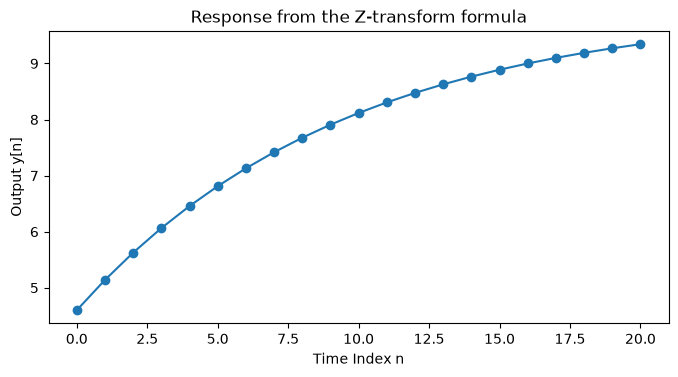

In [12]:
initial = 4
n = np.arange(21)
y = response_formula(n, decay, initial, input_level)
plt.figure(figsize=(8, 3.8))
plt.plot(n, y, "o-")
plt.xlabel("Time Index n")
plt.ylabel("Output y[n]")
plt.title("Response from the Z-transform formula")
plt.show()

**2C Answer**

This cell uses `decay` $=0.9$ and `input_level` $=1$ (left over from the 2A cell) with `initial` $=4$. The formula gives $4.6,\ 5.14,\ 5.63,\dots$ rising towards 10, which is exactly what iterating $y[n]=0.9\,y[n-1]+1$ from $y[-1]=4$ gives. (To compare the plots directly, set `initial = 4` in the 2A cell. The two cells have different defaults, 11 and 4.)

Checked numerically, $\max_n|\text{formula}-\text{simulation}|$:

| $a$ | $y_{-1}$ | $c$ | $n$ | max abs difference |
|---|---|---|---|---|
| 0.9 | 4 | 1 | 0–20 | $1.8\times10^{-15}$ |
| 0.9 | 11 | 1 | 0–50 | $3.6\times10^{-15}$ |
| 0.5 | 1 | 1 | 0–50 | 0 |
| −0.5 | 4 | 1 | 0–50 | 0 |
| 1.1 | 4 | 1 | 0–50 | $2.3\times10^{-13}$ (values up to 1800, so relative $10^{-16}$) |
| 0.99 | 11 | 2 | 0–200 | $8.5\times10^{-14}$ |

The differences are pure floating-point round-off, so **the Z-transform formula and the recursion agree**. Also, zero-input + zero-state = complete response to $1.8\times10^{-15}$. The only exception is $a=1$, where the formula is $0/0$ (numpy returns `nan` with "invalid value encountered in divide"). There you need the limit $c\,(n+1)$, giving $y[n]=y_{-1}+c\,(n+1)$.

The case $a=0.5,\ y_{-1}=1,\ c=1$ is exactly the lecture example $y[n]-\tfrac12y[n-1]=u[n],\ y[-1]=1$: zero-input $(\tfrac12)^{n+1}$, zero-state $2-(\tfrac12)^n$, total $2-(\tfrac12)^{n+1}=1.5,\ 1.75,\ 1.875,\dots$ The simulation matches.

### 2D. Zero-input Response

The expression we derived tells us something important. The output is the sum of two contributions. The first from the input signal (Zero-state response) and the second from the initial conditions (Zero-input response). 

To isolate the contribution of the initial condition, set $y[-1] = 4$ and the input to zero. This gives the **zero-input response**:
$$y_{\mathrm{zi}}[n]=y_{-1}a^{n+1},\qquad n\geq0.$$

Run the next cell to plot the zero-input response.

**Question:** How do the values of the input response change with the parameter `decay`?

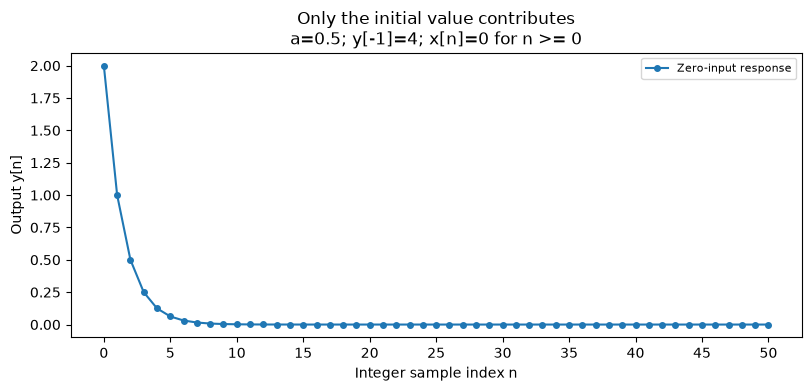

In [13]:
initial = 4
decay = 0.5
zero_input = lab.initial_condition_demo(decay, initial, input_level, view="zero_input", steps = 50)

**2D Answer**

$y_{zi}[n]=y_{-1}a^{n+1}=4a^{n+1}$ is a geometric sequence whose ratio is `decay`:

| `decay` $a$ | $y_{zi}[0..3]$ | $y_{zi}[10]$ | $y_{zi}[50]$ | behaviour |
|---|---|---|---|---|
| 0.5 (default) | 2, 1, 0.5, 0.25 | 0.002 | $2\times10^{-15}$ | halves every step, gone in ~10 samples |
| 0.9 | 3.6, 3.24, 2.92, 2.62 | 1.26 | 0.019 | slow decay |
| 0.99 | 3.96, 3.92, 3.88, 3.84 | 3.58 | 2.40 | very slow decay |
| 0 | 0, 0, 0, 0 | 0 | 0 | forgotten immediately (no memory) |
| −0.5 | −2, 1, −0.5, 0.25 | −0.002 | ≈0 | flips sign every sample, decays |
| −0.9 | −3.6, 3.24, −2.92, 2.62 | −1.26 | −0.019 | flips sign, decays slowly |
| 1 | 4, 4, 4, 4 | 4 | 4 | never forgets |
| −1 | −4, 4, −4, 4 | −4 | −4 | oscillates forever |
| 1.1 | 4.4, 4.84, 5.32, 5.86 | 11.4 | 517 | grows |
| 1.5 | 6, 9, 13.5, 20.3 | 346 | $3.8\times10^{9}$ | explodes |

- **$|a|$ sets the size:** $|a|<1$ means the initial condition dies out, $|a|=1$ means it persists, and $|a|>1$ means it grows. The closer $|a|$ is to 1, the longer the memory.
- **The sign of $a$ sets the shape:** $a<0$ flips the sign every sample.
- This is the pole $z=a$ of $H(z)=z/(z-a)$ again: **inside the unit circle means the transient dies out.** In continuous time, $e^{\lambda t}$ dies out iff $\mathrm{Re}\,\lambda<0$.

The zero-state response in the next cell ($a=0.5$) rises from 0 as $1,\ 1.5,\ 1.75,\ 1.875,\dots\to2=c/(1-a)$. Zero-input + zero-state = the full response (use `view="sum"` to see it).

#### Zero-state Response

Now restore the input but set the initial condition to zero ($y[-1] = 0$.) This gives the **zero-state response**:
$$y_{\mathrm{zs}}[n]=c\,\frac{1-a^{n+1}}{1-a},\qquad n\geq0,\quad a\ne1.$$
Run the next cell for the zero-state response.

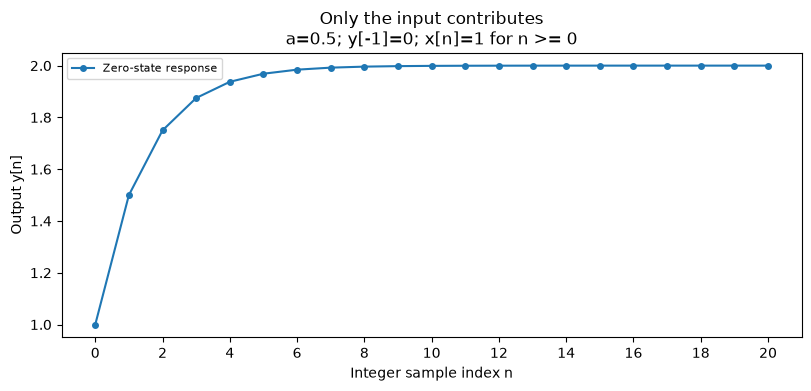

In [14]:
zero_state = lab.initial_condition_demo(decay, initial, input_level, view="zero_state")

## Q3 — Applications of LCCDEs

In Lab 3, we looked at applications of bandpass filters for denoising and a basic version of radio transmission. Unfortunately, these assumed the **idealized** bandpass filters which required that the entire signal was available to use before running our filter on it. In practice, we often only see the input signal one entry at a time. For example, in live radio, we cannot assume we have the entire transmission before we do our filtering. It turns out, difference equations help us get very good approximations of band-pass filters with just a finite number of samples. We will **approximate** bandpass filters with LCCDEs which only require a small number of input observations $x[n - M], x[(n - M) + 1], \dots, x[n]$ and the previous values of the output signal to produce the output signal at $n$, $y[n]$. We can produce the output signal piece by piece **without** observing the whole input signal $x$.

### 3A. Defining LCCDE Filters

Let $x[n]$ be the input signal. We will try to approximate the band-pass filter with difference equations of the following form:
$$y[n]=\sum_{k=0}^{M-1}h[k]x[n-k]$$
where $y[n]$ is the output of the filter. The $M$ coefficients $h[k]$ are its **taps**: each output uses the current input sample and the previous $M-1$ samples. You should think of $M$ as the amount of **memory** required to implement the filter. We will see soon how $M$ affects the quality of the filter.

As you can see, this filter can produce each output as soon as the current input sample arrives, using the stored past samples. From the lecture, we know that this rule defines an LTI system. What is its impulse response?

In the next cell below, we choose different values of $M$ and construct the system. The details of how to pick the $h$ are outside the scope of the class. We will mostly be concerned with how the impulse response behaves.

In [15]:
tap_counts = [9, 33, 513]  # Try different odd numbers of taps.
low, high = 100, 1000  # Hz: the band we want to retain

**3A Answer: the impulse response**

Feed in $x[n]=\delta[n]$:
$$y[n]=\sum_{k=0}^{M-1}h[k]\,\delta[n-k]=\begin{cases}h[n],&0\le n\le M-1\\0,&\text{otherwise.}\end{cases}$$
**The taps *are* the impulse response.** It has finite length $M$, so this is an **FIR (finite impulse response) filter**. The "difference equation" is just the convolution sum $y=h*x$ written out.

Its Z-transform (the transfer function):
$$H(z)=\sum_{k=0}^{M-1}h[k]z^{-k}=\frac{h[0]z^{M-1}+h[1]z^{M-2}+\dots+h[M-1]}{z^{M-1}}.$$
- **All $M-1$ poles are at $z=0$.** The ROC is $|z|>0$, which always contains the unit circle, so the filter is **always BIBO stable** ($\sum|h|$ is a finite sum). It is right-sided starting at $n=0$, so it is **causal**. The $M-1$ zeros do the shaping (for $M=33$: 32 zeros with $0.77\le|z|\le1.30$).
- The frequency response is $H$ on the unit circle: $H(e^{j\Omega})=\sum_k h[k]e^{-j\Omega k}$, with $\Omega=2\pi f/f_s$.
- It uses **no past outputs**. It is the special LCCDE with no $y[n-k]$ terms. (A filter *with* feedback, like 2A's $y[n]=a\,y[n-1]+x[n]$, is IIR. It can make sharp edges with far fewer coefficients, but it has poles away from the origin, so stability has to be checked.)
- How `lab_tools` picks $h$: `scipy.signal.firwin(M, [100, 1000], pass_zero=False, window="hamming")`. It takes the ideal band-pass impulse response (a difference of two sincs), keeps the middle $M$ samples, tapers them with a Hamming window, and shifts them to start at $n=0$. The taps are symmetric, so the filter is a pure **delay of $(M-1)/2$ samples** (`fir_demo` removes this delay before comparing).
- The cost of a large $M$: **memory** ($M-1$ stored past inputs), **computation** ($M$ multiply-adds per output sample), and **latency** ($(M-1)/2$ samples: 0.25 ms, 1 ms and 16 ms at 16 kHz for $M=9,33,513$).

Let's look at the frequency response of this system and compare that to what the ideal band-pass filter would have given us. 

**Question:** What happens as $M$ increases?

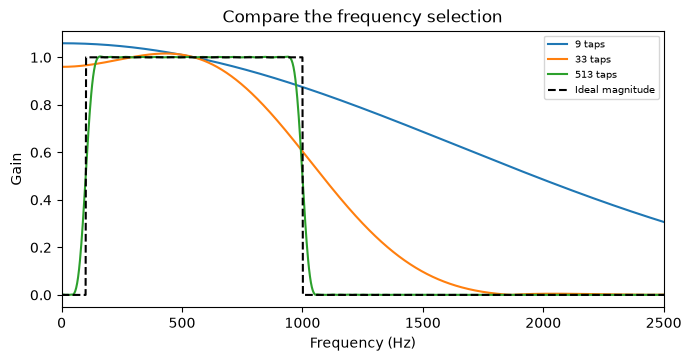

In [16]:
lab.fir_demo(tap_counts, low=low, high=high, view="response");

**3A Answer: what happens as $M$ increases?**

| $M$ | gain at 0 Hz | 100 Hz | 220 Hz | 440 Hz | 1000 Hz | 3600 Hz | 4100 Hz | where gain ≥ 0.5 | transition ≈ $3.3f_s/M$ |
|---|---|---|---|---|---|---|---|---|---|
| 9 | 1.06 | 1.06 | 1.05 | 1.02 | 0.88 | 0.073 | 0.028 | 0–1963 Hz | 5900 Hz |
| 33 | 0.96 | 0.97 | 0.99 | 1.02 | 0.61 | 0.001 | 0.001 | 0–1082 Hz | 1600 Hz |
| 513 | 0.002 | 0.50 | 1.00 | 1.00 | 0.50 | ≈0 | ≈0 | 100–1000 Hz | 103 Hz |

- **As $M$ grows, the response approaches the ideal box.** The edges get steeper (transition width $\propto1/M$, about $3.3f_s/M$ for a Hamming window), the passband gets flatter (±0.3% at $M=513$), and the stopband gets deeper (worst case above 2.5 kHz: −10 dB, −55 dB and −74 dB for $M=9, 33, 513$).
- **$M=9$ and $M=33$ are not really band-pass filters.** With a transition wider than 1 kHz they cannot make an edge at 100 Hz, so they act as **low-pass filters** that pass DC with gain ≈1. $M=9$ also only weakly suppresses the whistles (×0.073 = −23 dB at 3600 Hz).
- $M=513$ crosses 0.5 (−6 dB) exactly at 100 Hz and 1000 Hz, because a windowed-sinc design puts the band edges at half amplitude.
- **Why:** with only $M$ samples you cannot resolve frequency detail finer than about $f_s/M$ (31 Hz for $M=513$, 1.8 kHz for $M=9$). This is the same limit as the $N$-point DFT in Lab 3. A sharp edge in frequency needs a long impulse response in time: the ideal brick wall needs an infinitely long sinc.

### 3B. Recall the signals from Lab 3

In Lab 3, our denoising experiment used two seconds of an audio signal at frequencies 220 Hz and 440 Hz. It was corrupted by high-frequency whistles at 3600 Hz and 4100 Hz. In the plots below, we show a short section of each real-valued discrete-time audio signal and its DFT components.

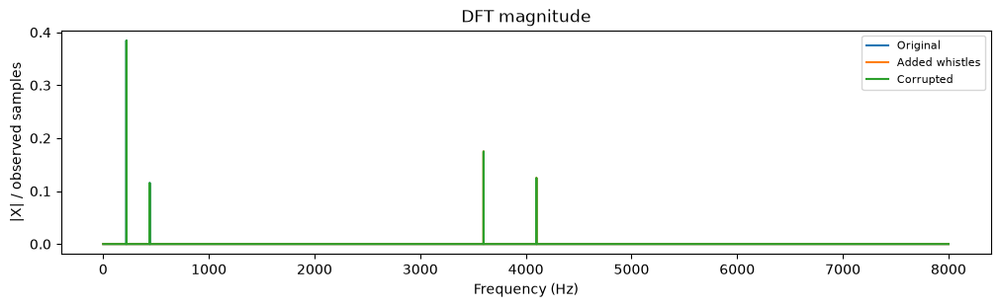

Original


Added whistles


Corrupted


In [17]:
audio_fs, audio_clean, _, audio_noisy = lab.audio_signals()
audio_noise = audio_noisy - audio_clean
lab.audio_comparison({
    "Original": audio_clean,
    "Added whistles": audio_noise,
    "Corrupted": audio_noisy,
}, audio_fs)

### 3C. Comparing Errors for Different Finite Filters

Here, we will measure the error between the filtered output and the original signal measured in root mean square (RMS) error. The plot also includes the error of the ideal filter from last week as a reference. Before measuring, we omit the edges of the recording to account for the boundary effects seen in the last exercise. Run the following cell and observe the error as $M$ increases.

**Question:** What happens as $M$ grows larger?

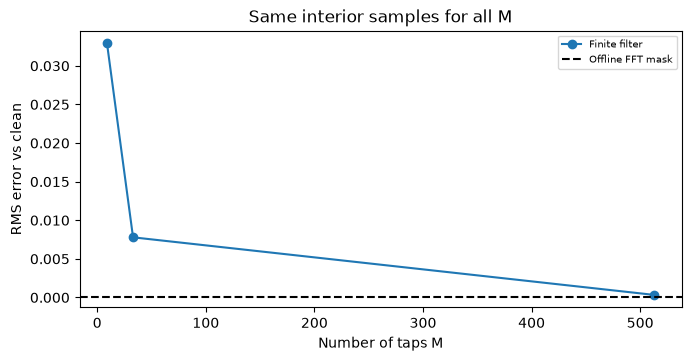

In [18]:
errors = lab.fir_demo(tap_counts, low=low, high=high, view="errors")

**3C Answer**

| | $M=9$ | $M=33$ | $M=513$ | ideal FFT mask (Lab 3) |
|---|---|---|---|---|
| RMS error vs clean | 0.0329 | 0.00779 | 0.000331 | $1.3\times10^{-13}$ |
| relative to clean RMS (0.568) | 5.8% | 1.4% | 0.06% | ≈0 |

**For the default taps, the error falls as $M$ grows** (about 100× from 9 to 513) and approaches the ideal filter. It never reaches it, because a finite $M$ always leaves some ripple and a transition band of nonzero width.

**But the error is not monotonic in $M$.** Trying more values:

| $M$ | 9 | 17 | 33 | 65 | 129 | 257 | 513 | 1025 | 2049 |
|---|---|---|---|---|---|---|---|---|---|
| RMS error | 0.0329 | 0.0682 | 0.0078 | **0.1218** | 0.0477 | 0.00077 | 0.00033 | 0.00077 | 0.000047 |

Why $M=65$ is *worse* than $M=9$:
- `firwin` scales each filter to gain 1 at the band centre (550 Hz). The short filters are effectively low-pass filters with gain ≈1 at 220 and 440 Hz, so the tones come through fine.
- This test signal has nothing below 100 Hz, so failing to reject below 100 Hz costs nothing here.
- At $M=65$–$129$ the filter starts to build the 100 Hz edge, but the edge is still 400–800 Hz wide, so it lands on the 220 Hz tone: the gain at 220 Hz is 0.78 for $M=65$ and 0.91 for $M=129$.
- Once the transition is narrower than the 120 Hz gap between 100 Hz and 220 Hz ($1.65f_s/M<120\Rightarrow M\gtrsim220$), the error stays small. In a sweep of $M=9,17,\dots,593$, every $M\ge201$ stayed below 1%.
- The whistle leakage is tiny for every $M\ge17$ (≤ $3.3\times10^{-4}$ RMS). Almost all the error is distortion of the 220 and 440 Hz tones. The 513 → 1025 bump is passband ripple at the 0.1% level.

The RMS number depends on what is in the test signal. If you also add a 50 Hz hum (amplitude 0.3), the short filters let it straight through. The errors become 0.23 ($M=9$), 0.20 ($M=33$), 0.085 ($M=129$), 0.028 ($M=257$) and 0.0007 ($M=513$).

(The 1024 samples trimmed from each end hide the filter's start-up transient, which lasts $M-1$ samples. That keeps the comparison fair up to $M=2049$.)

### 3D. Audio denoising

We will now go back to the original audio denoising demo from the previous lab. We saw before how the ideal filter successfully denoised the noisy sample. Let's see how well the difference equation versions perform. Listen to the outputs and record your observations:

1) Which values of $M$ produce the best outputs?
2) What happens when $M$ increases or decreases?

In [19]:
lab.fir_demo(tap_counts, low=low, high=high, view="audio");

Original


Corrupted


Filtered: 9 taps


Filtered: 33 taps


Filtered: 513 taps


**3D Answers** (every player uses the same gain, so loudness differences are real)

Output amplitude of each component ($|H|\times$ input amplitude):

| | 220 Hz tone | 440 Hz tone | 3600 Hz whistle | 4100 Hz whistle | whistles relative to the 220 Hz tone |
|---|---|---|---|---|---|
| corrupted input | 0.769 | 0.231 | 0.35 | 0.25 | −5 dB |
| $M=9$ | 0.807 | 0.236 | 0.025 | 0.007 | −30 dB |
| $M=33$ | 0.759 | 0.234 | 0.0004 | 0.0003 | −64 dB |
| $M=513$ | 0.770 | 0.231 | ≈0 | ≈0 | −83 dB |

1) **$M=513$ is the best** (closest to the original, 0.06% error), but **$M=33$ should already sound the same as the original**: at −64 dB the whistle is inaudible. $M=9$ removes most of the whistle, but a faint high whistle should still be audible, because it is only ~30 dB below the tone and a pure 3.6 kHz tone stands out. The tone itself is fine (about 5% louder).
2) **Decreasing $M$ lets the whistle back in.** **Increasing $M$ beyond ~33 makes no audible difference for this signal.** What you pay for a larger $M$ is delay and work: $(M-1)/2$ samples of latency (16 ms at $M=513$) and $M$ multiply-adds per output sample. Your ear does not notice a 1–5% gain error on the tone, but it does notice a pure whistle even when it is quiet. So "best by RMS" and "best by ear" are not the same ranking.

### 3E. Radio Transmission with Finite Bandpass Filters

In Lab 3, we explored the application of bandpass filters in enabling radio transmission of multiple signals. The core idea is that we multiply each of our signals with their own carrier signals which changes their frequencies profiles to disjoint bands. We then used a bandpass filter to isolate the changed band for each signal filtering out the components corresponding to the other signals. To recover the target signal, we then multiplied by the matching carrier again, and applied a low-pass filter to recover the original signal. Here, we replace the ideal filters from before with our finite filters.

We will now start with the two recordings from Lab 3 in `message1.wav`, and `message2.wav`. Replace the two files and try your own recordings in place of the two files. First, observe below that the original signals overlap significantly in their frequencies. Therefore, they cannot be added without interference between them.

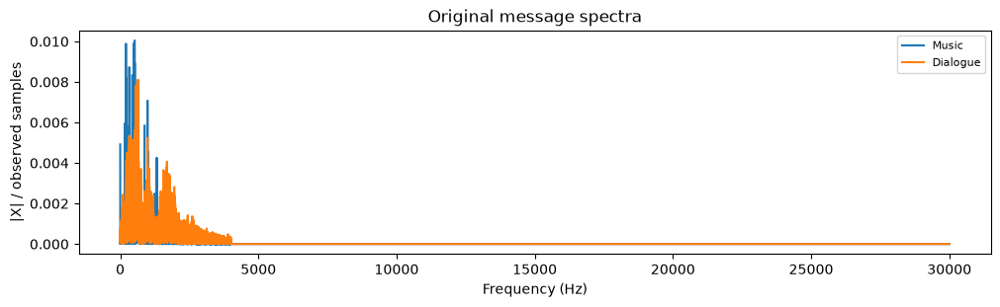

Music


Dialogue


In [20]:
radio_fs = 60000  # Samples per second.
# Change the bundled filenames and labels to try your own recordings.
radio_bandwidth = 4000  # Hz: message limit, channel half-width, and recovery cutoff.
radio_paths = ["message1.wav", "message2.wav"]
radio_labels = ["Music", "Dialogue"]
radio_messages = np.array([
    lab.load_audio(path, fs=radio_fs, duration=5)
    for path in radio_paths
])
# Limit the message bandwidth before moving it to a carrier frequency.
radio_messages = np.array([
    lab.fft_filter(message, radio_fs, 0, radio_bandwidth)
    for message in radio_messages
])
radio_t = np.arange(radio_messages.shape[1]) / radio_fs
radio_carriers = (12000, 24000)  # Hz.
lab.audio_comparison({
    radio_labels[0]: radio_messages[0],
    radio_labels[1]: radio_messages[1],
}, radio_fs, title="Original message spectra")

Next, we will multiply the two signals with their carrier frequencies to separate the two signals in the frequency domain. We see that after multiplication they occupy disjoint frequency bands. 

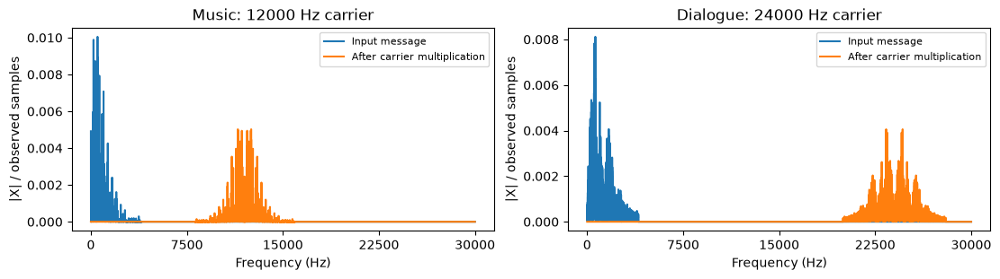

In [21]:
radio_channels = [
    message * np.cos(2 * np.pi * fc * radio_t)
    for message, fc in zip(radio_messages, radio_carriers)
]
fig, axes = plt.subplots(1, 2, figsize=(11, 3), constrained_layout=True)
for j, ax in enumerate(axes):
    lab.spectrum(ax, radio_messages[j], radio_fs, "Input message")
    lab.spectrum(ax, radio_channels[j], radio_fs, "After carrier multiplication")
    ax.set_title("%s: %g Hz carrier" % (radio_labels[j], radio_carriers[j]))
    ax.set_xticks(np.linspace(0, radio_fs / 2, 5))
plt.show()

We will now add the two modulated signals (the signals obtained after multiplication with the carrier signals) together to obtain the combined signal that we will transmit.

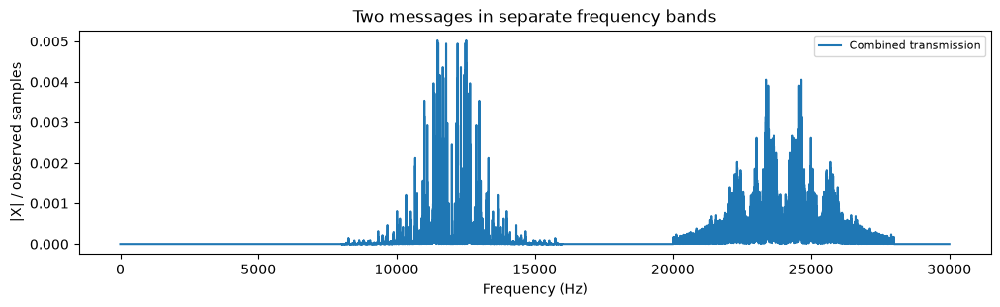

Combined transmission


In [22]:
radio_combined = radio_channels[0] + radio_channels[1]
lab.audio_comparison({"Combined transmission": radio_combined}, radio_fs, title="Two messages in separate frequency bands")

We will now look at approximations to the band-pass filter for different values of $M$. Run the following cells and observe how our approximations get better as $M$ increases. Run the next three cells and listen to the recovered messages. For each value of $M$, we will obtain the message recovered by using our finite bandpass filter instead of the idealized bandpass and lowpass filters. Listen to each of the recovered signals and note the change in quality as $M$ increases.

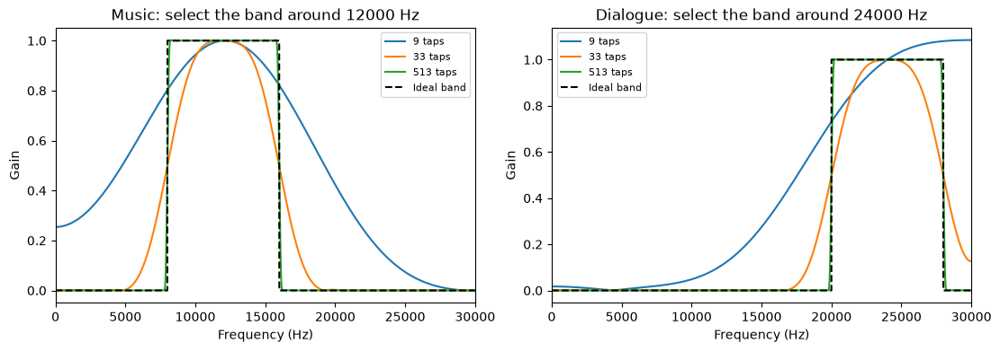

In [23]:
lab.fir_radio_demo(radio_messages, fs=radio_fs, lengths=tap_counts, carriers=radio_carriers, view="response", labels=radio_labels, bandwidth=radio_bandwidth);

**Observations: band-pass responses** ($f_s=60$ kHz, music band 8–16 kHz)

| $M$ | gain at 12 kHz ($f_c$) | 10 kHz / 14 kHz | 8 kHz / 16 kHz (band edges) | 20 kHz (start of the dialogue band) | 24 kHz (dialogue carrier) |
|---|---|---|---|---|---|
| 9 | 1.00 | 0.94 / 0.96 | 0.80 / 0.82 | 0.42 | 0.12 |
| 33 | 1.00 | 0.93 / 0.93 | 0.50 / 0.50 | 0.003 | 0.000 |
| 513 | 1.00 | 1.00 / 1.00 | 0.50 / 0.50 | 0.000 | 0.000 |

$M=9$ is so wide (transition ≈ $3.3\cdot60000/9\approx22$ kHz) that it is barely a band-pass at all: 42% of the gain is still there where the other channel starts. $M=33$ already separates the channels (transition ≈ 6 kHz, half of which fits in the 4 kHz guard gap at 16–20 kHz). $M=513$ is essentially the ideal box.

The recovered and original signals are plotted here. Note the change in recovery quality as $M$ grows larger.

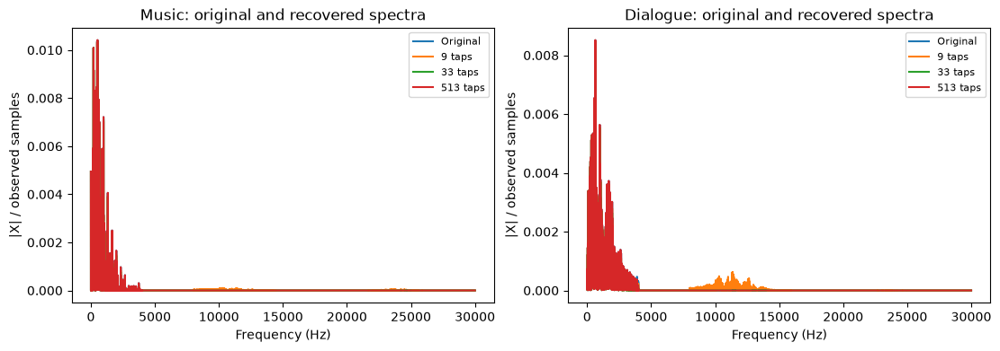

In [24]:
radio_results = lab.fir_radio_demo(radio_messages, fs=radio_fs, lengths=tap_counts, carriers=radio_carriers, view="recovery", labels=radio_labels, bandwidth=radio_bandwidth)

Finally, run the next cell and listen to the recovered signals:

**Question:** For what values of $M$ does the recovery quality qualitatively degrade?

In [25]:
lab.fir_radio_demo(radio_messages, fs=radio_fs, lengths=tap_counts, carriers=radio_carriers, view="audio", labels=radio_labels, bandwidth=radio_bandwidth);

Original Music


Music: 9 taps


Music: 33 taps


Music: 513 taps


Original Dialogue


Dialogue: 9 taps


Dialogue: 33 taps


Dialogue: 513 taps


**3E Answer**

Recovery error (RMS error ÷ the message's own RMS), plus how much of the *other* channel leaks in:

| $M$ | total delay ($M-1$ samples) | Music error | Dialogue error | crosstalk into Music | crosstalk into Dialogue |
|---|---|---|---|---|---|
| 9 | 0.13 ms | 3.8% | 11.3% | 3.2% | 0.7% |
| 17 | 0.27 ms | 4.6% | 12.3% | 0.02% | ≈0 |
| 33 | 0.53 ms | 2.3% | 8.6% | ≈0 | ≈0 |
| 65 | 1.1 ms | 0.9% | 3.8% | ≈0 | ≈0 |
| 129 | 2.1 ms | 0.5% | 2.3% | ≈0 | ≈0 |
| 513 | 8.5 ms | 0.1% | 1.1% | ≈0 | ≈0 |

**Recovery quality degrades for small $M$, roughly $M\lesssim33$.**
- **$M=9$ is clearly worse.** The recovered signals contain junk at 8–16 kHz (the orange hump in the dialogue spectrum above), so you should hear a high-pitched hiss/garble on top of the message. 86% of the dialogue's error energy and 73% of the music's is above 4.5 kHz.
  - For the **dialogue**, the junk is mostly its own copy at $2f_c=48$ kHz. At $f_s=60$ kHz that copy aliases to $60-48=12$ kHz, and the 9-tap low-pass (gain 0.13 at 12 kHz) does not remove it.
  - For the **music**, the junk is the dialogue channel leaking through the wide band-pass, shifted to 8–16 kHz.
- **$M=33$** has no out-of-band junk. Its error is all in-band: the dialogue should sound **muffled**, because the 4 kHz recovery low-pass is already down to 0.76 at 3 kHz.
- From $M\approx65$–$129$ both messages are within a few percent, and $M=513$ is essentially identical to the original.

Why:
- **Crosstalk** needs the band-pass transition to fit inside the 4 kHz guard gap. At $f_s=60$ kHz the transition is about $3.3\cdot60000/M$ (22 kHz for $M=9$, 6 kHz for $M=33$, 386 Hz for $M=513$). Half of it must be below 4 kHz, so $M\gtrsim25$, which matches crosstalk vanishing between 17 and 33.
- **The remaining error is the message's own high frequencies** being cut by the sloping filter edges (both filters are at 0.5 at the 4 kHz edge). Dialogue has 6% of its energy above 2 kHz, but the music has only 0.4% (26% of the music's energy is below 300 Hz). That is why the dialogue suffers more, and why the music survives even 9 taps.
- **Radio needs fewer taps than the 3C denoiser** because what matters is the transition width *relative to $f_s$*: here ~4 kHz out of 60 kHz, there ~120 Hz out of 16 kHz.
- **The trade-off:** a larger $M$ means more delay ($M-1$ samples through the two filters: 8.5 ms at $M=513$), more memory and more computation (513 taps × 60 000 samples/s ≈ 31 million multiply-adds per second, *per filter*). For live radio, a few hundred taps is a good compromise.